# Homework 1

In this assignment, we will connect a small calculation by hand with the output of a program and learn how to choose a useful test.

The steps are:

- **A:** find the output shape and one output value
- **B:** complete a short implementation and compare it with SciPy
- **C:** identify an error
- **D:** choose a question of our own and carry out a small investigation
- Optional feedback at the end

**Related material:** Practice 3, exercises 1.1, 1.2 and 5.1. You can also consult the worked exercises covered in the tutorials.

## Before we start

The assignment uses NumPy, SciPy and Matplotlib.
To install them, run `%pip install numpy scipy matplotlib` in a separate cell and restart the kernel.

The starter notebook runs even with the answers left blank. `None` means “no answer has been provided yet”. Here, `np.nan` is a placeholder for a missing number. The helper functions are provided. Write your code between `### TODO: ADD YOUR CODE HERE` and `### END of TODO`.

In [1]:
### TODO: ADD YOUR CODE HERE
student_name = "Name Surname"  # Replace with your full name.
student_id = "12345678"  # Replace with your student ID.
### END of TODO

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

## Step A

We use the input and kernel from exercise 1.1. Indexing starts at 0. In `X[m, n]`, the first index selects a row and the second selects a column.

In [3]:
X = np.array([[1, 2, 0],
              [3, 1, -1],
              [2, 0, 1]], dtype=float)
H = np.array([[1, 2],
              [-1, 0]], dtype=float)
print("Input X:\n", X)
print("Kernel H:\n", H)

Input X:
 [[ 1.  2.  0.]
 [ 3.  1. -1.]
 [ 2.  0.  1.]]
Kernel H:
 [[ 1.  2.]
 [-1.  0.]]


$X$ is the input matrix and $H$ is the kernel, which contains the filter weights. $y[m,n]$ is one output value. For this kernel:

$$y[m,n]=\sum_{i=0}^{1}\sum_{j=0}^{1}H[i,j]X[m-i,n-j].$$

The indices $m,n$ select the output position. The indices $i,j$ run through the rows and columns of the kernel. The two sums mean that we add four products. Every value of $X$ outside the given matrix is taken to be zero.

### A1. Output shape
If the input has $M$ rows and $N$ columns, and the kernel has $M_h$ rows and $N_h$ columns, the full output has shape

$$(M+M_h-1,\ N+N_h-1).$$

The subscript $h$ distinguishes the kernel dimensions from the input dimensions. We write the shape as `(rows, columns)`. This notation is called a **tuple** and keeps the two values together. For example, a matrix with 2 rows and 5 columns has shape `(2, 5)`.

Find the output shape for the matrices above and fill in `shape_by_hand` in the same format.

### A2. One value by hand
In class, we calculated $y[1,1]=5$. Now find **$y[1,2]$**, the entry in the second row and third column of the output. First, complete the table in the separate answer cell below, without calling SciPy.

Add the four products and write the result in `value_by_hand`.

**Answer A2**

| $(i,j)$ | $H[i,j]$ | position $X[1-i,2-j]$ | input value | product |
|---|---:|---|---:|---:|
| $(0,0)$ | 1 | [1,2] | -1 | -1 |
| $(0,1)$ | 2 | [1,1] | 1 | 2 |
| $(1,0)$ | −1 | [0,2] | 0 | 0 |
| $(1,1)$ | 0 | [0,1] | 2 | 0 |


In [4]:
### TODO: ADD YOUR CODE HERE
shape_by_hand = (4,4)  # Replace with the output (rows, columns) as a tuple, e.g. (1, 2).
value_by_hand = 1.0  # Replace with the value y[1, 2].
### END of TODO

print("Predicted shape:", shape_by_hand)
print("Calculated y[1, 2]:", value_by_hand)

Predicted shape: (4, 4)
Calculated y[1, 2]: 1.0


## Step B
### B1. Two-dimensional convolution

`conv2d_full(x, h)` computes the full convolution of two non-empty, real-valued, two-dimensional arrays. The lowercase names `x, h` are the function parameters. When we call it with `X, H`, it will use the matrices from A.

Complete **both TODO regions**:

1. The input indices `mi, nj` corresponding to `m, n, i, j`.
2. The product added to `y[m, n]`.

The loops, output shape, boundary check and `return` are already provided.

In NumPy, negative indices read elements from the end of an array. The boundary check ensures that only samples inside the input contribute to the calculation, consistent with zero extension.

Follow the formula in step A. In this formula, the flip is expressed through the input indices.

In [5]:
def conv2d_full(x, h):
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    M, N = x.shape
    Mh, Nh = h.shape
    y = np.zeros((M + Mh - 1, N + Nh - 1), dtype=float)

    for m in range(y.shape[0]):
        for n in range(y.shape[1]):
            for i in range(Mh):
                for j in range(Nh):
                    ### TODO: ADD YOUR CODE HERE
                    mi, nj = m-i, n-j
                    ### END of TODO
                    if mi is None or nj is None:
                        return np.full(y.shape, np.nan)
                    if 0 <= mi < M and 0 <= nj < N:
                        ### TODO: ADD YOUR CODE HERE
                        y[m, n] += h[i,j] * x[mi,nj]
                        ### END of TODO
    return y

### B2. Convolution using SciPy

SciPy provides a ready-made implementation. With `mode="full"`, we keep the entire output. With `boundary="fill", fillvalue=0`, we set the values outside the input to zero. SciPy already handles convolution, so we pass it the original kernel.

`compare_outputs` displays the shapes of the two results. If they match, it computes the maximum absolute difference, which is the largest distance between two corresponding values. `np.allclose` returns `True` when all corresponding values agree within a small numerical tolerance.

A difference very close to zero indicates numerical agreement for this example. Small differences, such as `1e-15`, can arise from the order of floating-point operations.

While `np.nan` remains in the function's TODO regions, the difference is shown as `nan` and numerical agreement as `False`.

In [6]:
def compare_outputs(actual, reference, label):
    print(label)
    print("Our output shape:", actual.shape)
    print("Reference shape:", reference.shape)
    if actual.shape != reference.shape:
        print("The shapes differ. Check the dimensions.")
        return
    print("Maximum absolute difference:", np.max(np.abs(actual - reference)))
    print("Numerical agreement:", np.allclose(actual, reference))

Y_reference = convolve2d(X, H, mode="full", boundary="fill", fillvalue=0)
Y_mine = conv2d_full(X, H)
compare_outputs(Y_mine, Y_reference, "The example from A")

print("Reference output:\n", Y_reference)
print("Our computed output:\n", Y_mine)
print("Our predicted shape:", shape_by_hand)
print("Reference shape:", Y_reference.shape)
print("y[1, 2] by hand:", value_by_hand)
print("Reference y[1, 2]:", Y_reference[1, 2])

The example from A
Our output shape: (4, 4)
Reference shape: (4, 4)
Maximum absolute difference: 0.0
Numerical agreement: True
Reference output:
 [[ 1.  4.  4.  0.]
 [ 2.  5.  1. -2.]
 [-1.  3.  2.  2.]
 [-2.  0. -1.  0.]]
Our computed output:
 [[ 1.  4.  4.  0.]
 [ 2.  5.  1. -2.]
 [-1.  3.  2.  2.]
 [-2.  0. -1.  0.]]
Our predicted shape: (4, 4)
Reference shape: (4, 4)
y[1, 2] by hand: 1.0
Reference y[1, 2]: 1.0


### B3. Checking correctness

To check our algorithm, we can design small tests that examine its results on different types of input. This lets us try the implementation in more cases. In programming, these are called “unit tests” and are useful for checking corner cases, error handling and similar situations.

Testing different inputs can reveal errors that do not appear in the original example and give us greater confidence in our implementation. Here, we will examine the following case: the first example has a square 3×3 input and a square 2×2 kernel. If we accidentally use the number of rows in place of the number of columns, the error may go unnoticed because the two numbers are equal. Let's see what happens with a 4×6 input and a 3×2 kernel, whose dimensions differ. The full output has shape `(6, 7)`, so the number of rows and columns also differs in the result.

In [7]:
rng = np.random.default_rng(4)
x_rect = rng.normal(size=(4, 6))
h_rect = rng.normal(size=(3, 2))
y_rect_ref = convolve2d(x_rect, h_rect, mode="full", boundary="fill", fillvalue=0)
y_rect_mine = conv2d_full(x_rect, h_rect)
compare_outputs(y_rect_mine, y_rect_ref, "Rectangular data")

Rectangular data
Our output shape: (6, 7)
Reference shape: (6, 7)
Maximum absolute difference: 0.0
Numerical agreement: True


### B4. A test of your own

Choose another small input and a kernel to test a different case of `conv2d_full`. Briefly explain why you chose these data and what you expect to happen. Fill in the two arrays in the code cell and compare the output with SciPy. Then add to your answer whether the result agrees with your prediction.

**Test Case Selection:** We selected a single-row input vector of shape $1 \times 3$ (`x_check = [[1, 2, 3]]`) and a single-column kernel vector of shape $2 \times 1$ (`h_check = [[2], [-1]]`). This tests the corner case where one dimension of each 2D array is equal to $1$ (row vector convolved with a column vector, i.e., an outer-product-like structure).

**Prediction:** According to the spatial dimension formula $(M+M_h-1,\ N+N_h-1)$, we expect the output shape to be $(1+2-1,\ 3+1-1) = (2, 3)$. Specifically, the first row of the output should be the input multiplied by $2$, yielding `[2, 4, 6]`, and the second row should be the input multiplied by $-1$, yielding `[-1, -2, -3]`.

**Conclusion:** After execution, `conv2d_full` produces an output of shape `(2, 3)` with values `[[2., 4., 6.], [-1., -2., -3.]]`. The maximum absolute difference against SciPy is `0.0` (`np.allclose` returns `True`), confirming both our analytical prediction and the correctness of the implementation on degenerate 1D-like shapes.


In [8]:
### TODO: ADD YOUR CODE HERE
x_check = np.array([[1,2,3]], dtype=float)  # Enter a small two-dimensional np.array.
h_check = np.array([[2],[-1]], dtype=float)  # Enter the kernel as a two-dimensional np.array.
### END of TODO

if x_check is not None and h_check is not None:
    y_check = conv2d_full(x_check, h_check)
    y_check_ref = convolve2d(x_check, h_check, mode="full", boundary="fill", fillvalue=0)
    compare_outputs(y_check, y_check_ref, "Our own test")
    print("Our computed output:\n", y_check)
    print("Reference output:\n", y_check_ref)

Our own test
Our output shape: (2, 3)
Reference shape: (2, 3)
Maximum absolute difference: 0.0
Numerical agreement: True
Our computed output:
 [[ 2.  4.  6.]
 [-1. -2. -3.]]
Reference output:
 [[ 2.  4.  6.]
 [-1. -2. -3.]]


## Step C
### C1. Identifying an error

`conv2d_candidate` contains an error in its calculation. It runs and returns the correct shape. **First, look at its results.**

We will compare this function with SciPy, first for a kernel whose weights are all 1, and then for the non-symmetric `H` from A. Predict which case makes it easier to spot an error in the flip.

Leave the function unchanged for now.

In [9]:
def conv2d_candidate(x, h):
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    M, N = x.shape
    Mh, Nh = h.shape
    y = np.zeros((M + Mh - 1, N + Nh - 1), dtype=float)
    for m in range(y.shape[0]):
        for n in range(y.shape[1]):
            for i in range(Mh):
                for j in range(Nh):
                    mi, nj = m - i, n - j
                    if 0 <= mi < M and 0 <= nj < N:
                        y[m, n] += h[Mh - 1 - i, Nh - 1 - j] * x[mi, nj]
    return y

In [10]:
H_symmetric = np.ones((2, 2))
for label, kernel in [("Symmetric kernel", H_symmetric),
                      ("Non-symmetric kernel", H)]:
    expected = convolve2d(X, kernel, mode="full", boundary="fill", fillvalue=0)
    candidate = conv2d_candidate(X, kernel)
    compare_outputs(candidate, expected, label)

Symmetric kernel
Our output shape: (4, 4)
Reference shape: (4, 4)
Maximum absolute difference: 0.0
Numerical agreement: True
Non-symmetric kernel
Our output shape: (4, 4)
Reference shape: (4, 4)
Maximum absolute difference: 7.0
Numerical agreement: False


#### C1.1. The first kernel

Does the kernel whose entries are all 1 change when rotated by 180°? Fill in your answer in the next cell. Then briefly explain how this affects our ability to detect an incorrect flip.

In [11]:
### TODO: ADD YOUR CODE HERE
gamma1_kernel_changes = False  # True if it changes, False if it stays the same.
### END of TODO

**Explanation C1.1**

A kernel with all coefficients equal to $1$ is completely symmetric across both axes and remains invariant when rotated by $180^\circ$ (flipped horizontally and vertically). Consequently, using such a kernel masks any bug related to index reversal: the unflipped and flipped kernels are identical, producing the exact same numerical output and preventing us from detecting the error.


#### C1.2. Finding the incorrect term

In the line that updates `y[m, n]`, which term reads the kernel with reversed indices? Write the `h[...]` term from the incorrect function inside the quotation marks. We will correct the function in C3.

In [12]:
### TODO: ADD YOUR CODE HERE
gamma1_faulty_term = "h[Mh-1-i,Nh-1-j]"  # The h[...] term you identified.
### END of TODO

#### C1.3. Checking the shape

Is the correct output shape enough to confirm that the function computes convolution correctly? Fill in your answer and justify it using the results you observed.

In [13]:
### TODO: ADD YOUR CODE HERE
gamma1_shape_sufficient = False  # True if checking the shape is enough, False if another check is needed.
### END of TODO

**Explanation C1.3**

No, verifying the output shape alone is not sufficient. As demonstrated in the test with the non-symmetric kernel `H`, `conv2d_candidate` returns the expected `(4, 4)` output shape, yet its numerical values are incorrect (yielding a maximum absolute difference of `7.0` compared to SciPy and `False` for numerical agreement). Output dimensions only depend on array allocation, not on the accuracy of the inner-loop arithmetic.

### C2. Testing with a unit impulse

A useful test has a result that we can easily predict. We use `[[1]]` as the input matrix, with zero values outside it. This input is the unit impulse at the origin of the two axes.

Convolving this impulse with the kernel `H` returns `H` itself. The only nonzero input sample has value 1, so it reproduces the kernel entries at the corresponding output positions.

Run the next cell and compare the two matrices:

1. Does `conv2d_candidate` return the expected matrix `H`?
2. Describe how the returned matrix differs from `H`.

In [14]:
impulse = np.array([[1.0]])
impulse_output = conv2d_candidate(impulse, H)
print("Expected output H:\n", H)
print("Output of conv2d_candidate:\n", impulse_output)

Expected output H:
 [[ 1.  2.]
 [-1.  0.]]
Output of conv2d_candidate:
 [[ 0. -1.]
 [ 2.  1.]]


In [15]:
### TODO: ADD YOUR CODE HERE
gamma2_matches_kernel = False  # True if the two matrices are equal, False if they differ.
### END of TODO

**Description of the difference in C2**

The matrix returned by `conv2d_candidate` (`[[0., -1.], [2., 1.]]`) is the original kernel `H` (`[[1., 2.], [-1., 0.]]`) rotated by $180^\circ$—that is, flipped both vertically (along rows) and horizontally (along columns). Because the input indices `m - i` and `n - j` already account for the convolution flip, reversing the kernel indices a second time via `h[Mh - 1 - i, Nh - 1 - j]` cancels out the flip and computes cross-correlation instead of convolution.


### C3. Correcting the error

The next cell contains a second version of the function, so that we can keep the original incorrect implementation as an example. Correct the line between the TODO comments. Then run the definition again, followed by the two comparisons below.

In [16]:
def conv2d_repaired(x, h):
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    M, N = x.shape
    Mh, Nh = h.shape
    y = np.zeros((M + Mh - 1, N + Nh - 1), dtype=float)
    for m in range(y.shape[0]):
        for n in range(y.shape[1]):
            for i in range(Mh):
                for j in range(Nh):
                    mi, nj = m - i, n - j
                    if 0 <= mi < M and 0 <= nj < N:
                        ### TODO: ADD YOUR CODE HERE
                        y[m, n] += h[i,j] * x[mi, nj]
                        ### END of TODO
    return y

In [17]:
compare_outputs(conv2d_repaired(impulse, H), H, "After the correction: impulse")
compare_outputs(conv2d_repaired(X, H), Y_reference, "After the correction: original input")

After the correction: impulse
Our output shape: (2, 2)
Reference shape: (2, 2)
Maximum absolute difference: 0.0
Numerical agreement: True
After the correction: original input
Our output shape: (4, 4)
Reference shape: (4, 4)
Maximum absolute difference: 0.0
Numerical agreement: True


## Step D

Choose **a question about the material covered so far in the tutorials (Lectures 1–3)**. Design a small experiment that will help you understand your chosen topic better.

### Choosing a topic

Choose something that interests you or that you found difficult and would like to spend more time on. You can start from an exercise we have covered in class, from the practice sheets, or from a question of your own.

Some possible directions are:

- Visualization: Create a visual representation that helps explain a mathematical concept or method.

- Experimentation: Modify a familiar exercise or vary the parameters of a problem and examine how the result changes.

- Implementation: Investigate alternative implementations of a method or the behaviour of an algorithm.

- Verification: Check a solution, a hypothesis or a computational result.

These directions are suggestions. You can follow any other approach that interests you, as long as it relates to the course material.

### Designing the experiment

The aim is to investigate a specific question and explain what you observe. Use a known solution or a plot as a starting point for that investigation.

Design a **small test, comparison or visualization** that helps you answer your question. Consider what you will change, what you will keep fixed and what you expect to observe.

**Example**

One investigation we discussed in the tutorial was: “How do the eigenvalues affect the shape of the ellipse?”

We can keep one eigenvalue fixed, vary the other and plot the corresponding ellipses. Comparing the results lets us examine how the semiaxes change and what this means for the sensitivity of the problem.

In exercise 2.2 of Practice 1, we examined what affects the size and proportions of the ellipse. Keeping the eigenvalues $12$ and $0.03$ fixed, we plot the curves for $c=1,4,9$, where $c$ is the increase in cost above its minimum value. We check whether the ratio $a_2/a_1$ stays the same as the ellipse grows, where $a_1$ and $a_2$ are the lengths of its two semiaxes. Alternatively, we keep $c=1$, the first eigenvalue at $12$ and the axis directions fixed. We vary the second eigenvalue, plot the ellipse again and examine how the semiaxis ratio changes. In each experiment, we vary one quantity so that we can explain its effect on the result.

This is an example of a small investigation: we start with a question, change something specific and observe the result.

Your experiment can be simple and produce an ordinary result. Even if the result contradicts your initial prediction, it is still a useful observation.

### Tools

Your investigation must include **Python code that runs in the notebook**. You may use any library you like, as well as AI tools such as ChatGPT, Claude or Gemini. Using AI is allowed and encouraged as an aid to understanding a concept, designing an experiment, creating code or interpreting results.

We encourage you to choose what you want to investigate first, based on your own questions and interests, and then use the tools to explore it.

### Deliverables

#### D1. Question and initial prediction

What question did you choose, why does it interest you and what did you expect to happen?

**Research Question:** How does increasing the spatial dimension $K \times K$ of a normalized uniform averaging kernel (box filter, where every weight equals $1/K^2$) affect its 2D convolution with a bright square pulse in terms of:
1. Edge sharpness and spatial spread,
2. Peak (maximum) output intensity, and
3. Conservation of the total sum of array elements?

**Motivation:** In Step C, we examined a symmetric kernel filled with ones. In image and signal processing, normalized uniform kernels are widely used as low-pass smoothing filters (box blur). We want to understand both visually and quantitatively how the kernel scale $K$ interacts with the characteristic size of an object in the input signal.

**Initial Prediction:**
1. As $K$ increases ($K = 2, 4, 6$), the full output dimensions will expand according to $(M+K-1,\ N+K-1)$, and the sharp boundaries of the square pulse will become progressively blurrier (wider transition band).
2. As long as the kernel size $K$ is less than or equal to the width of the bright square ($4 \times 4$), the maximum value at the center of the output will remain $1.0$, because the kernel can fit entirely inside the region of ones. Once $K$ exceeds $4$ (i.e., $K=6$), the peak value will drop below $1.0$ because the kernel footprint will inevitably overlap with surrounding zeros.
3. The total sum of all elements in the output array will remain invariant and equal to the sum of the input array ($16.0$), because the kernel weights sum to $1.0$.

#### D2. Method and tools

Describe what you changed, what you kept fixed and how you investigated your question. If you used AI, report the model and prompts.

**Constant Parameters:**
- The input array $X$ of shape $10 \times 10$, containing a centered $4 \times 4$ square pulse of ones ($1.0$) surrounded by zeros ($0.0$). The total sum of the input elements is $\sum X = 16.0$.
- The normalization constraint of the smoothing kernel $H_K$, where all weights are set to $1/K^2$ so that $\sum_{i,j} H_K[i,j] = 1.0$.

**Varied Parameter:**
- The spatial dimension $K$ of the square kernel $H_K$ ($K \times K$), tested across three values: $K = 2$, $K = 4$, and $K = 6$.

**Methodology and Tools:**
We implemented the experiment in Python using `NumPy` and `Matplotlib`, utilizing our verified `conv2d_full` function from Step B. For each value of $K$, we compute the full 2D convolution, log the output shape, maximum intensity, and total element sum in a summary table, and visualize the resulting 2D arrays side by side as heatmaps (`viridis` colormap with fixed range $[0, 1]$).

**Use of AI:**
We used **Google Gemini** to help structure the experimental design, format the visualization code, and translate the documentation into English.
- *Prompts used:* 
  1. *"Design and explain step by step an experiment for Step D in Python using NumPy and Matplotlib where we vary a single kernel parameter while keeping the 2D input signal constant."*
 

#### D3. Experiment code

Include your Python code in the next code cell.

Input X: Shape = (10, 10), Max Value = 1.0000, Sum of Elements = 16.0000

Kernel Size (KxK)    | Output Shape   | Max Value    | Output Sum  
------------------------------------------------------------------
2x2                  | (11, 11)       | 1.0000       | 16.0000     
4x4                  | (13, 13)       | 1.0000       | 16.0000     
6x6                  | (15, 15)       | 0.4444       | 16.0000     


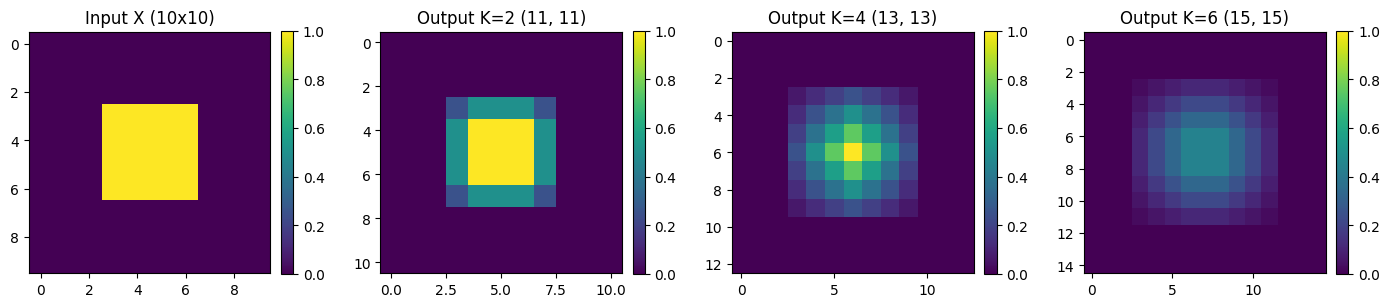

In [18]:
### TODO: ADD YOUR CODE HERE
# 1. Define constant input X (10x10) with a centered 4x4 square pulse
X_exp = np.zeros((10, 10), dtype=float)
X_exp[3:7, 3:7] = 1.0

# Values of the varied parameter K (kernel size KxK)
K_values = [2, 4, 6]

print(f"Input X: Shape = {X_exp.shape}, Max Value = {np.max(X_exp):.4f}, Sum of Elements = {np.sum(X_exp):.4f}\n")
print(f"{'Kernel Size (KxK)':<20} | {'Output Shape':<14} | {'Max Value':<12} | {'Output Sum':<12}")
print("-" * 66)

# 2. Set up figure (1 row, 4 columns: Input + 3 Outputs)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

im0 = axes[0].imshow(X_exp, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Input X (10x10)")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# 3. Run experiment for each K
for idx, K in enumerate(K_values, start=1):
    # Normalized uniform averaging kernel KxK (weights sum to 1)
    H_k = np.ones((K, K), dtype=float) / (K ** 2)
    
    # Compute full 2D convolution using our function from Step B
    Y_k = conv2d_full(X_exp, H_k)
    
    # Print metrics
    print(f"{f'{K}x{K}':<20} | {str(Y_k.shape):<14} | {np.max(Y_k):<12.4f} | {np.sum(Y_k):<12.4f}")
    
    # Plot heatmap
    im = axes[idx].imshow(Y_k, cmap="viridis", vmin=0, vmax=1)
    axes[idx].set_title(f"Output K={K} {Y_k.shape}")
    plt.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()
### END of TODO

#### D4. Result and observation

Present the result as code output, a table, a plot or another suitable format. You can refer to the output of D3. Make it clear what you are comparing or checking. Explain what you conclude, whether the result agrees with your prediction and whether it answers your original question. Add anything you would like to investigate further, if applicable.

**Results and Observations (referencing D3 output):**
1. **Output Shape and Edge Smoothing:** Both the printed table and the heatmaps confirm that the output dimensions grow from `(10, 10)` in the input to `(11, 11)`, `(13, 13)`, and `(15, 15)` for $K = 2, 4, 6$, respectively, matching $(10+K-1,\ 10+K-1)$. Visually, as $K$ increases, the sharp step transition at the boundary of the square turns into a broader, smoother gradient ramp.
2. **Peak Intensity Attenuation:** For $K=2$ and $K=4$, the maximum output value remains exactly `1.0000` because the $2 \times 2$ and $4 \times 4$ kernels fit completely inside the $4 \times 4$ square pulse at the center position. However, when $K=6$, the maximum value drops to `0.4444` ($16 / 36 = 4/9$), since even when centered, the $6 \times 6$ kernel averages all $16$ ones together with $20$ surrounding zeros.
3. **Sum Preservation (Conservation Property):** Across all three kernels ($K=2, 4, 6$), the total sum of the output elements remains constant at `16.0000`, matching the input sum $\sum X = 16.0$. This numerically verifies the fundamental convolution property $\sum_{m,n} (X * H)[m,n] = \left(\sum_{m,n} X[m,n]\right)\left(\sum_{i,j} H[i,j]\right)$.

**Conclusion:** The experimental findings completely confirm our initial predictions and clearly illustrate the spatial and energetic effects of box-filter scale in 2D convolution.

**Future Work:** As a next step, it would be interesting to corrupt the input square pulse with additive white Gaussian noise (AWGN) and measure the Signal-to-Noise Ratio (SNR) improvement as a function of $K$, quantifying the fundamental trade-off between noise suppression and edge blurring.

## Before submitting the assignment

- Select **Restart Kernel and Run All** and save the notebook **with cell outputs visible**, including the tables, plots and printed results from step D. Executing the code cells and saving their outputs are part of the assessment. Do not select **Clear Outputs** before submitting.
- Keep the incorrect results of `conv2d_candidate` as part of the example.
- Your code must run without errors and produce correct results. If the code for a question fails to run, no credit is awarded for that question.
- Make sure you have entered your details in the identification cell at the beginning of the notebook.
- Optionally, use the last cell to give feedback on the assignment in 1–2 sentences. You can comment on the content, the time it took, the difficulty or a particular question you still have about the assignment.

### Optional: Give us feedback!

How much did each part of the tutorial help your understanding?

A. The analytical exercises

B. Connecting the analytical exercises with a Python implementation

C. The open-ended experimental part

In [19]:
### TODO: ADD YOUR CODE HERE
# Rate from 0 (Not at all) to 10 (Very much).

feedback_A = None  # analytical exercises
feedback_B = None  # connecting analytical exercises with a Python implementation
feedback_C = None  # open-ended experimental part
### END of TODO

_You can write any other comments here._